# Practical No. 05: Image Generation using Pretrained Stable Diffusion

**Name:** Mit Jangid  
**PRN:** 202401110072  
**Batch:** A1  
**Subject:** Generative AI

## Aim
Implement a pretrained Stable Diffusion model using Hugging Face Diffusers to generate images from text prompts. Analyze the impact of inference steps, guidance scale, and sampling methods on generated-image quality.

## Distinct implementation
This notebook uses the publicly available **DreamShaper 8** checkpoint (`Lykon/dreamshaper-8`), a Stable-Diffusion-1.5-based fine-tuned model, rather than the reference report's `segmind/tiny-sd`. Experiments use a new set of themes and a compact, controlled comparison design.

## Runtime
Use a Google Colab **T4 GPU** if available. The notebook uses FP16, 384×384 images, attention slicing, and reuses one loaded pipeline. Actual runtime depends on GPU availability and memory.

## 1. Check GPU and install required libraries

In [1]:
!pip -q install -U diffusers transformers accelerate safetensors

In [2]:
import os, time, gc, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from diffusers import StableDiffusionPipeline, DDIMScheduler, EulerDiscreteScheduler, PNDMScheduler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU not detected. In Colab, select Runtime > Change runtime type > T4 GPU.")

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.


PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


## 2. Load the pretrained model
DreamShaper 8 is a Stable-Diffusion-1.5-based checkpoint. The pipeline is loaded once and reused for all experiments.

In [4]:
MODEL_ID = "Lykon/dreamshaper-8"
DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True
)
pipe = pipe.to(DEVICE)
pipe.enable_attention_slicing()

print("Loaded:", MODEL_ID)
print("Device:", DEVICE)
print("Dtype:", DTYPE)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

CLIPFeatureExtractor appears to have been deprecated in transformers. Using CLIPImageProcessor instead.


Loaded: Lykon/dreamshaper-8
Device: cuda
Dtype: torch.float16


## 3. Define a reproducible image-generation helper
A fixed seed is used for controlled comparisons. The helper returns the generated image and elapsed generation time.

In [5]:
IMAGE_SIZE = 384
BASE_PROMPT = (
    "A serene alpine lake surrounded by pine forests and snow-capped mountains, "
    "soft morning sunlight, realistic landscape photography, detailed natural textures"
)
NEGATIVE_PROMPT = "blurry, low quality, distorted, text, watermark, oversaturated"

def generate_image(prompt, steps=25, guidance=7.5, seed=SEED,
                   negative_prompt=NEGATIVE_PROMPT, scheduler_name=None):
    if scheduler_name is not None:
        scheduler_map = {
            "PNDM": PNDMScheduler,
            "DDIM": DDIMScheduler,
            "Euler": EulerDiscreteScheduler
        }
        scheduler_cls = scheduler_map[scheduler_name]
        pipe.scheduler = scheduler_cls.from_config(pipe.scheduler.config)

    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    start = time.time()
    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        width=IMAGE_SIZE,
        height=IMAGE_SIZE,
        generator=generator
    )
    elapsed = time.time() - start
    return result.images[0], elapsed

def show_images(images, titles, suptitle=None):
    plt.figure(figsize=(5 * len(images), 5))
    for i, (img, title) in enumerate(zip(images, titles), 1):
        plt.subplot(1, len(images), i)
        plt.imshow(img)
        plt.title(title)
        plt.axis("off")
    if suptitle:
        plt.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

## 4. Basic text-to-image generation

  0%|          | 0/25 [00:00<?, ?it/s]

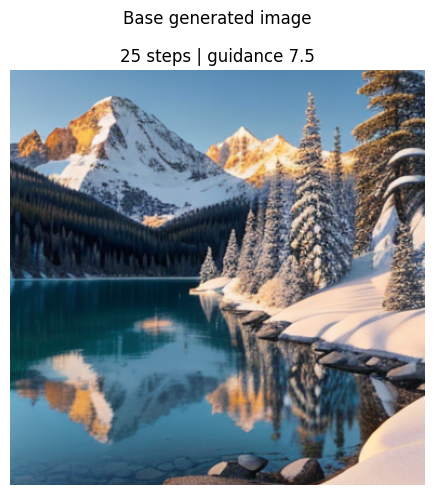

Generation time: 4.85 seconds


In [6]:
base_image, base_time = generate_image(BASE_PROMPT, steps=25, guidance=7.5, seed=SEED)
show_images([base_image], ["25 steps | guidance 7.5"], "Base generated image")
print(f"Generation time: {base_time:.2f} seconds")

## 5. Experiment 1 — Effect of inference steps
Keep the prompt, guidance scale, scheduler, and seed fixed. Vary only the number of denoising steps.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

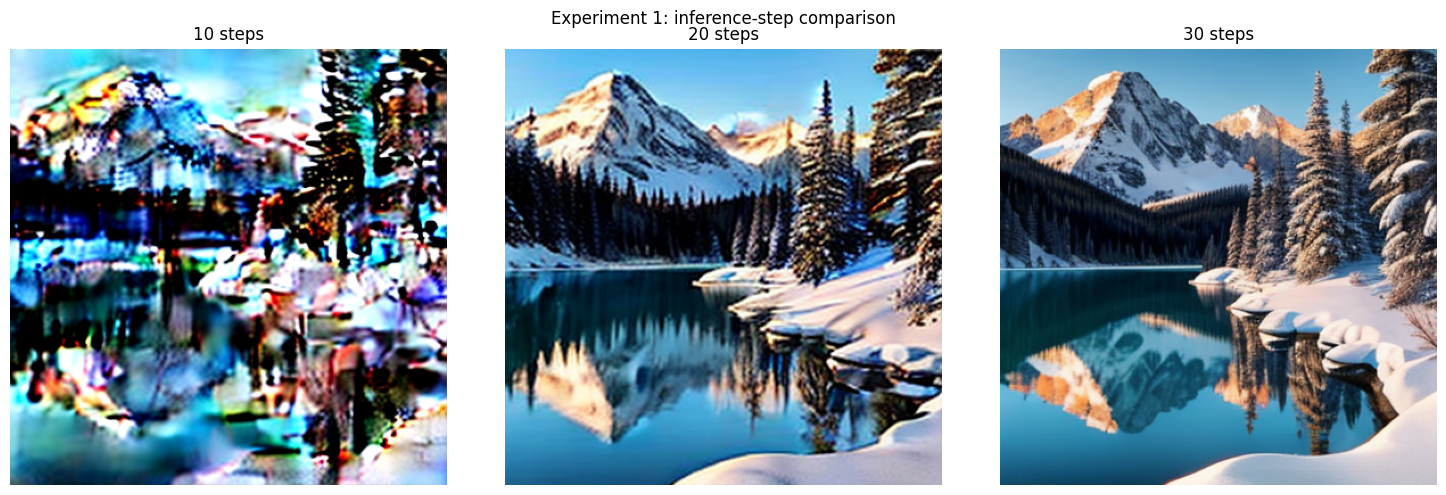

,Inference steps,Generation time (sec)
0,10,1.80
1,20,2.63
2,30,3.83


In [7]:
step_values = [10, 20, 30]
step_images, step_times = [], []
for step_count in step_values:
    image, elapsed = generate_image(BASE_PROMPT, steps=step_count, guidance=7.5,
                                    seed=SEED, scheduler_name="PNDM")
    step_images.append(image)
    step_times.append(elapsed)

show_images(step_images, [f"{s} steps" for s in step_values],
            "Experiment 1: inference-step comparison")
step_results = pd.DataFrame({"Inference steps": step_values, "Generation time (sec)": np.round(step_times, 2)})
display(step_results)

**Observation guide:** Compare structure, detail, prompt alignment, and generation time. More steps may improve refinement, but improvement can become small relative to added time.

## 6. Experiment 2 — Effect of guidance scale
Keep prompt, inference steps, scheduler, and seed fixed. Vary only classifier-free guidance scale.

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

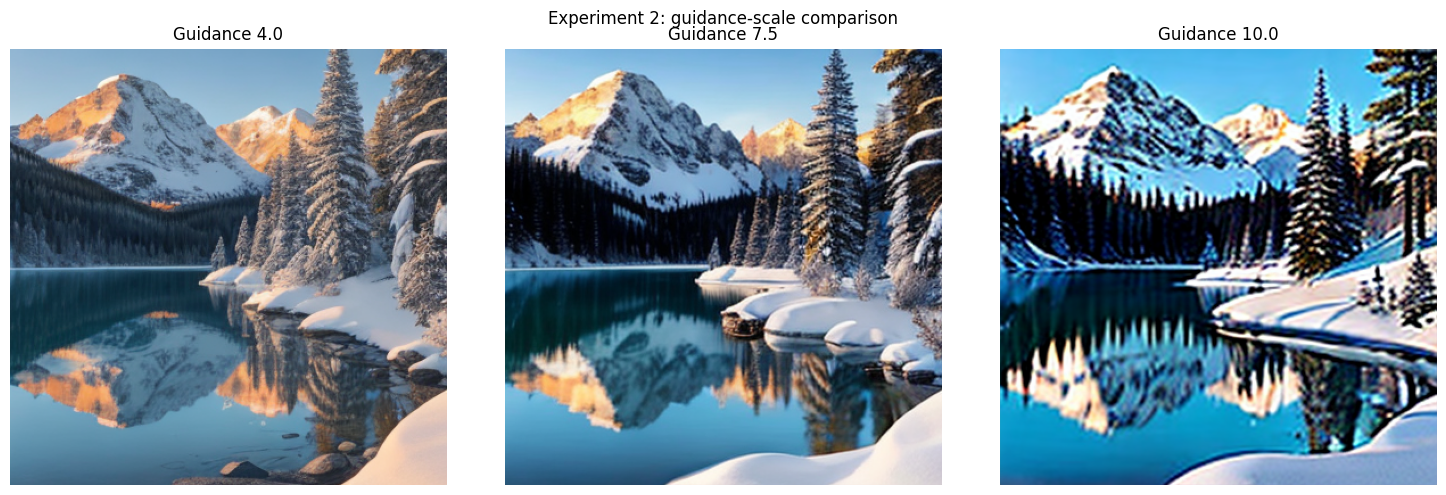

,Guidance scale,Generation time (sec)
0,4.0,3.42
1,7.5,3.30
2,10.0,3.31


In [8]:
guidance_values = [4.0, 7.5, 10.0]
guidance_images, guidance_times = [], []
for scale in guidance_values:
    image, elapsed = generate_image(BASE_PROMPT, steps=25, guidance=scale,
                                    seed=SEED, scheduler_name="PNDM")
    guidance_images.append(image)
    guidance_times.append(elapsed)

show_images(guidance_images, [f"Guidance {g}" for g in guidance_values],
            "Experiment 2: guidance-scale comparison")
guidance_results = pd.DataFrame({"Guidance scale": guidance_values,
                                 "Generation time (sec)": np.round(guidance_times, 2)})
display(guidance_results)

**Observation guide:** Low guidance may follow the prompt less strongly. Higher guidance can strengthen prompt alignment but may produce harsh contrast or less natural images. Judge the actual outputs.

## 7. Experiment 3 — Compare sampling schedulers
Use the same prompt, seed, inference steps, and guidance scale. Only the scheduler changes.

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

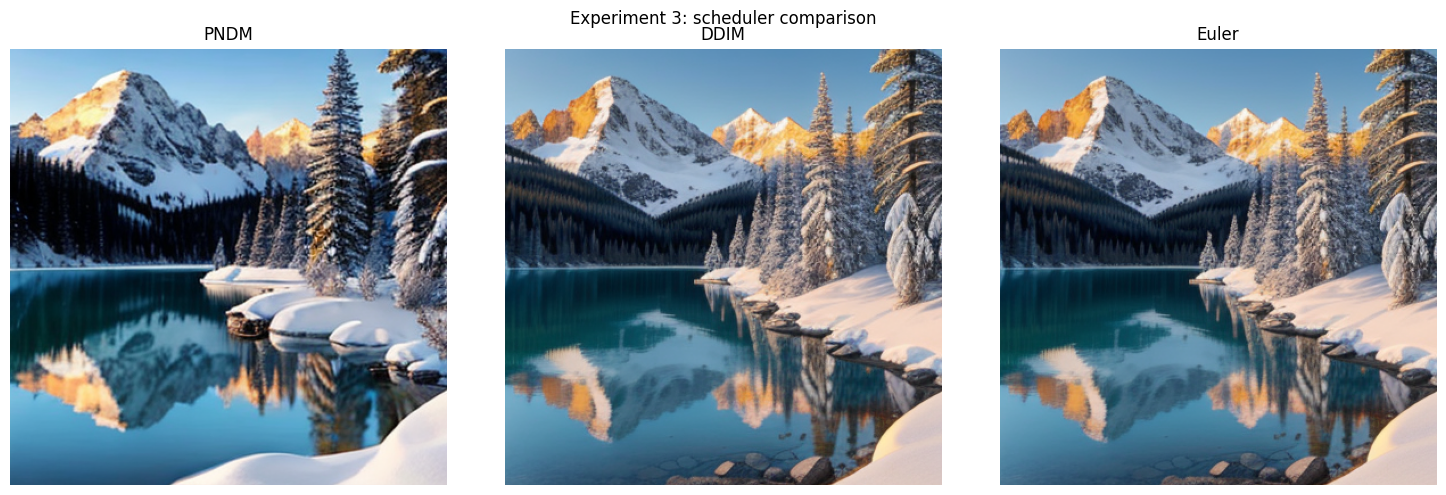

,Scheduler,Generation time (sec)
0,PNDM,4.01
1,DDIM,3.24
2,Euler,3.23


In [9]:
scheduler_names = ["PNDM", "DDIM", "Euler"]
scheduler_images, scheduler_times = [], []
for scheduler_name in scheduler_names:
    image, elapsed = generate_image(BASE_PROMPT, steps=25, guidance=7.5,
                                    seed=SEED, scheduler_name=scheduler_name)
    scheduler_images.append(image)
    scheduler_times.append(elapsed)

show_images(scheduler_images, scheduler_names, "Experiment 3: scheduler comparison")
scheduler_results = pd.DataFrame({"Scheduler": scheduler_names,
                                  "Generation time (sec)": np.round(scheduler_times, 2)})
display(scheduler_results)

## 8. Experiment 4 — Prompt engineering and negative prompts
Use three distinct subjects and compare a basic prompt with a more descriptive prompt. Then compare generation with and without a negative prompt.

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

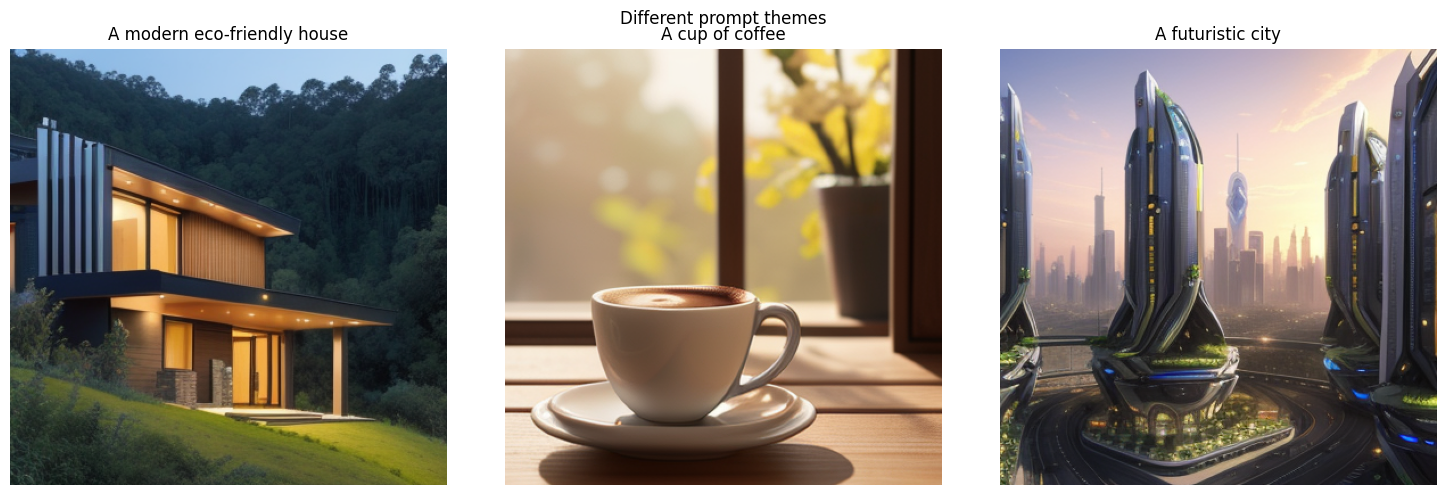

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

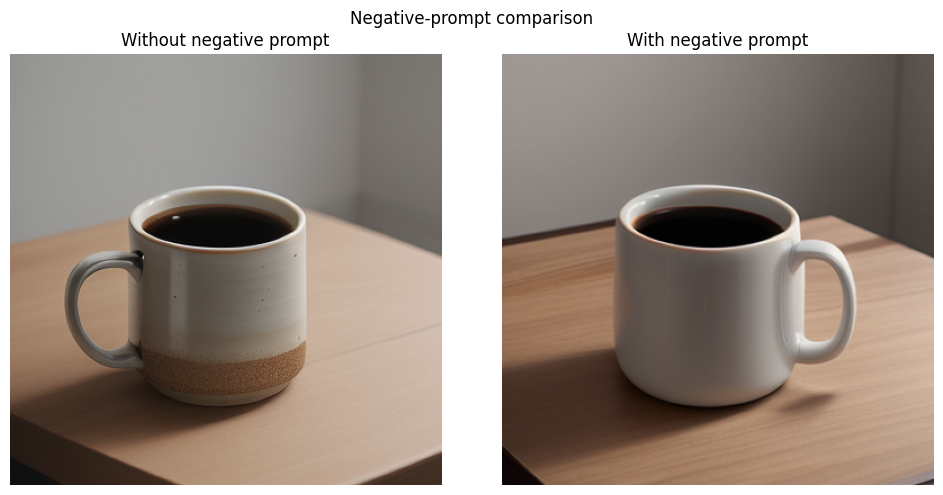

In [10]:
prompt_pairs = [
    ("A modern eco-friendly house",
     "A modern eco-friendly house built into a green hillside, timber and glass architecture, "
     "solar panels, lush native plants, golden-hour architectural photography"),
    ("A cup of coffee",
     "A ceramic cup of cappuccino on a wooden cafe table, delicate latte art, warm window light, "
     "shallow depth of field, professional product photography"),
    ("A futuristic city",
     "A futuristic sustainable city with vertical gardens, clean public transit, glass towers, "
     "sunset atmosphere, cinematic wide-angle concept art")
]

prompt_images, prompt_titles = [], []
for short_prompt, detailed_prompt in prompt_pairs:
    img, _ = generate_image(detailed_prompt, steps=25, guidance=7.5, seed=SEED)
    prompt_images.append(img)
    prompt_titles.append(short_prompt)

show_images(prompt_images, prompt_titles, "Different prompt themes")

test_prompt = "A handcrafted ceramic coffee mug on a minimal studio table, product photography"
without_negative, t1 = generate_image(test_prompt, steps=25, guidance=7.5,
                                       seed=123, negative_prompt="")
with_negative, t2 = generate_image(test_prompt, steps=25, guidance=7.5,
                                    seed=123, negative_prompt=NEGATIVE_PROMPT)
show_images([without_negative, with_negative],
            ["Without negative prompt", "With negative prompt"],
            "Negative-prompt comparison")

## 9. Consolidated generation-time results
This table combines measured runtimes from the controlled experiments.

In [11]:
all_results = pd.concat([
    step_results.assign(Experiment="Inference steps").rename(columns={"Inference steps": "Setting"}),
    guidance_results.assign(Experiment="Guidance scale").rename(columns={"Guidance scale": "Setting"}),
    scheduler_results.assign(Experiment="Scheduler").rename(columns={"Scheduler": "Setting"})
], ignore_index=True)
display(all_results[["Experiment", "Setting", "Generation time (sec)"]])

,Experiment,Setting,Generation time (sec)
0,Inference steps,10,1.80
1,Inference steps,20,2.63
2,Inference steps,30,3.83
3,Guidance scale,4.0,3.42
4,Guidance scale,7.5,3.30
5,Guidance scale,10.0,3.31
6,Scheduler,PNDM,4.01
7,Scheduler,DDIM,3.24
8,Scheduler,Euler,3.23


## 10. Save generated images and experimental tables

In [12]:
os.makedirs("stable_diffusion_outputs", exist_ok=True)

base_image.save("stable_diffusion_outputs/base_landscape.png")
for value, image in zip(step_values, step_images):
    image.save(f"stable_diffusion_outputs/steps_{value}.png")
for value, image in zip(guidance_values, guidance_images):
    image.save(f"stable_diffusion_outputs/guidance_{str(value).replace('.', '_')}.png")
for name, image in zip(scheduler_names, scheduler_images):
    image.save(f"stable_diffusion_outputs/scheduler_{name.lower()}.png")

all_results.to_csv("stable_diffusion_outputs/generation_time_results.csv", index=False)
print("Saved generated images and experiment results.")

Saved generated images and experiment results.


## 11. Observations and conclusion

After executing the notebook, write observations based on your own generated outputs:

- **Inference steps:** Describe how image detail and generation time changed across 10, 20, and 30 steps.
- **Guidance scale:** Describe prompt alignment and visual quality at guidance values 4.0, 7.5, and 10.0.
- **Schedulers:** Compare PNDM, DDIM, and Euler using the same prompt and seed.
- **Prompt engineering:** Explain how adding subject details, style, lighting, and quality descriptors changed the generated images.
- **Negative prompts:** Record whether the negative prompt reduced unwanted visual features.

**Conclusion:** A pretrained Stable Diffusion pipeline was used for text-to-image generation. Controlled experiments examined inference steps, classifier-free guidance, scheduler choice, and prompt engineering. The generated images and measured runtimes provide the basis for comparing the settings.

*Do not fill in observations or timing values until the notebook has been run; use the actual outputs.*